# Installing geopandas for map and choropleth functionality

In [1]:
%pip install geopandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
# Check that geopandas installed and what version was installed.
print(gpd.__version__)

1.2.0


In [4]:
# Load U.S. state boundary data from the Census Bureau
states = gpd.read_file(
    "https://www2.census.gov/geo/tiger/GENZ2024/shp/cb_2024_us_state_500k.zip"
)
# Preview the first five rows
print(states.head())

  STATEFP   STATENS      GEOIDFQ GEOID STUSPS          NAME LSAD  \
0      35  00897535  0400000US35    35     NM    New Mexico   00   
1      46  01785534  0400000US46    46     SD  South Dakota   00   
2      06  01779778  0400000US06    06     CA    California   00   
3      21  01779786  0400000US21    21     KY      Kentucky   00   
4      01  01779775  0400000US01    01     AL       Alabama   00   

          ALAND       AWATER  \
0  314198519809    726531289   
1  196341670967   3387563375   
2  403673433805  20291632828   
3  102266755818   2384136185   
4  131185561946   4581813708   

                                            geometry  
0  POLYGON ((-109.05017 31.48, -109.04984 31.4995...  
1  POLYGON ((-104.05788 44.9976, -104.05078 44.99...  
2  MULTIPOLYGON (((-118.60442 33.47855, -118.5987...  
3  MULTIPOLYGON (((-89.40565 36.52816, -89.39868 ...  
4  MULTIPOLYGON (((-88.05338 30.50699, -88.05109 ...  


## Now we are going to load in our Pandas dataframe. 

In [5]:
df = pd.read_csv("Race by State.csv", encoding="utf-8")

In [6]:
df.sample(5)

,Notes,States,States Code,Race,Race Code,Population
115,NaN,Kansas,20.0,Native Hawaiian or Other Pacific Islander,NHOPI,22303.0
296,NaN,Tennessee,47.0,Black or African American,2054-5,5888717.0
171,NaN,Mississippi,28.0,Native Hawaiian or Other Pacific Islander,NHOPI,10096.0
210,NaN,New Jersey,34.0,American Indian or Alaska Native,1002-5,366306.0
117,NaN,Kansas,20.0,More than one race,M,486291.0


In [7]:
df.head(10)

,Notes,States,States Code,Race,Race Code,Population
0,NaN,Alabama,1.0,American Indian or Alaska Native,1002-5,189858.0
1,NaN,Alabama,1.0,Asian,A,411086.0
2,NaN,Alabama,1.0,Black or African American,2054-5,6785631.0
3,NaN,Alabama,1.0,Native Hawaiian or Other Pacific Islander,NHOPI,30330.0
4,NaN,Alabama,1.0,White,2106-3,17520840.0
5,NaN,Alabama,1.0,More than one race,M,496098.0
6,Total,Alabama,1.0,NaN,NaN,25433843.0
7,NaN,Alaska,2.0,American Indian or Alaska Native,1002-5,573448.0
8,NaN,Alaska,2.0,Asian,A,250482.0
9,NaN,Alaska,2.0,Black or African American,2054-5,135645.0


## Now we are going to load in the combined dataset and try to visualize it.

In [8]:
df_comb=pd.read_csv("STATE_MMR_COMB_DATA.csv",encoding="UTF-8")

In [9]:
df_comb.head(10)

,State,STATE_MMR,BLACK_POP,BLACK_MMR,STRUCT_ RACISM_SCORE
0,Alabama,30.4,0.25,55.8,-1.13
1,Alaska,NaN,0.02,NaN,-1.27
2,Arizona,28.4,0.04,45.5,-0.66
3,Arkansas,32.7,0.14,72.1,-0.89
4,California,10.8,0.05,36.5,1.06
5,Colorado,16.0,0.04,NaN,0.83
6,Connecticut,14.4,0.10,NaN,2.04
7,Delaware,NaN,0.21,NaN,-0.44
8,Florida,22.7,0.14,49.8,-0.80
9,Georgia,28.5,0.30,51.3,-1.20


### Designating all rows and limit columns.

In [10]:
df_comb = df_comb.iloc[:,:5]

In [11]:
df_comb.head(10)

,State,STATE_MMR,BLACK_POP,BLACK_MMR,STRUCT_ RACISM_SCORE
0,Alabama,30.4,0.25,55.8,-1.13
1,Alaska,NaN,0.02,NaN,-1.27
2,Arizona,28.4,0.04,45.5,-0.66
3,Arkansas,32.7,0.14,72.1,-0.89
4,California,10.8,0.05,36.5,1.06
5,Colorado,16.0,0.04,NaN,0.83
6,Connecticut,14.4,0.10,NaN,2.04
7,Delaware,NaN,0.21,NaN,-0.44
8,Florida,22.7,0.14,49.8,-0.80
9,Georgia,28.5,0.30,51.3,-1.20


## Start descriptive Stats Visualization

In [12]:
df_sorted = df_comb.sort_values("BLACK_MMR", ascending=False)
df_topten = df_sorted.head(10)
df_topten

,State,STATE_MMR,BLACK_POP,BLACK_MMR,STRUCT_ RACISM_SCORE
15,Kansas,21.0,0.05,106.7,0.35
41,Tennessee,41.8,0.15,88.3,-0.93
29,New Jersey,24.8,0.12,78.8,2.22
35,Oklahoma,28.7,0.06,75.6,-0.90
3,Arkansas,32.7,0.14,72.1,-0.89
17,Louisiana,39.4,0.30,66.5,-0.74
39,South Carolina,30.3,0.24,66.4,-0.69
23,Mississippi,37.5,0.36,63.8,-1.17
32,North Carolina,28.6,0.20,62.8,-0.64
45,Virginia,32.4,0.18,61.8,-0.68


In [13]:
type(df_topten.loc[45,"BLACK_MMR"])

numpy.float64

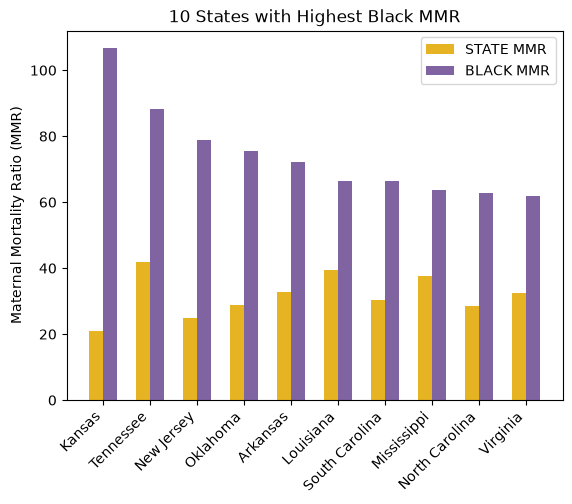

In [14]:
import numpy as np
# Top 10 States Black MMR
fig, ax = plt.subplots()
width = 0.3
x = np.arange(10)
y = ["BLACK_MMR","STATE_MMR"]
ax.bar(x-width/2, df_topten["STATE_MMR"], width, label = "STATE MMR", color="#E6B422")
ax.bar(x+width/2, df_topten["BLACK_MMR"], width, label = "BLACK MMR", color="#8064A2")
ax.set_xticks(x)
ax.set_xticklabels(df_topten["State"], rotation = 45, ha = "right")
ax.legend()
ax.set_ylabel("Maternal Mortality Ratio (MMR)")
ax.set_title("10 States with Highest Black MMR")
plt.show()

In [15]:
# Evaluating STATE_MMR_COMB_DATA.csv
# Check the columns in my maternal mortality dataset
print(df_comb.columns.tolist())
print(df_comb.head())

['State', 'STATE_MMR', 'BLACK_POP', 'BLACK_MMR', 'STRUCT_ RACISM_SCORE']
        State  STATE_MMR  BLACK_POP  BLACK_MMR  STRUCT_ RACISM_SCORE
0     Alabama       30.4       0.25       55.8                 -1.13
1      Alaska        NaN       0.02        NaN                 -1.27
2     Arizona       28.4       0.04       45.5                 -0.66
3    Arkansas       32.7       0.14       72.1                 -0.89
4  California       10.8       0.05       36.5                  1.06


In [16]:
# Merge maternal mortality data with U.S. state boundaries.

map_data = states.merge(
    df_comb,
    left_on = "NAME",
    right_on="State",
    how = "left"
)

# Check the merged dataset
print(map_data[["NAME", "STATE_MMR", "BLACK_MMR"]].head())

           NAME  STATE_MMR  BLACK_MMR
0    New Mexico       28.9        NaN
1  South Dakota       21.4        NaN
2    California       10.8       36.5
3      Kentucky       28.0       47.8
4       Alabama       30.4       55.8


In [17]:
df_comb[["State", "STATE_MMR"]].head(10)

,State,STATE_MMR
0,Alabama,30.4
1,Alaska,NaN
2,Arizona,28.4
3,Arkansas,32.7
4,California,10.8
5,Colorado,16.0
6,Connecticut,14.4
7,Delaware,NaN
8,Florida,22.7
9,Georgia,28.5


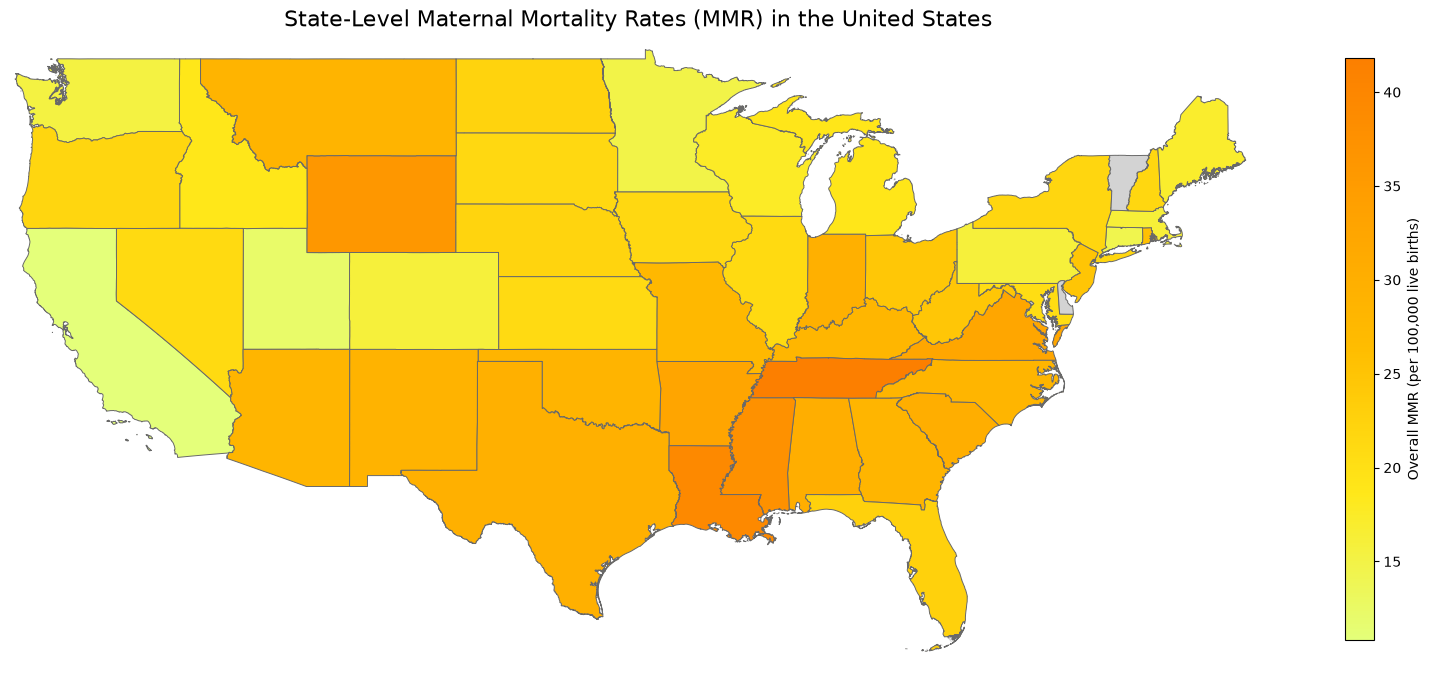

In [18]:
# Create a gold-gradient map of overall maternal mortality rates by state

fig, ax = plt.subplots(figsize = (16,10))

map_data.plot(
    column = "STATE_MMR",
    cmap ="Wistia",
    linewidth = 0.7,
    edgecolor ="dimgray",
    legend =True,
    missing_kwds = {
        "color": "lightgrey",
        "label": "No data"
    },
    legend_kwds={
        "label": "Overall MMR (per 100,000 live births)",
        "shrink": 0.6
    },
    ax=ax
)

ax.set_title(
    "State-Level Maternal Mortality Rates (MMR) in the United States",
    fontsize = 16
)


ax.set_xlim(-125, -66)
ax.set_ylim(24, 50)
ax.axis("off")
plt.tight_layout()
plt.show()

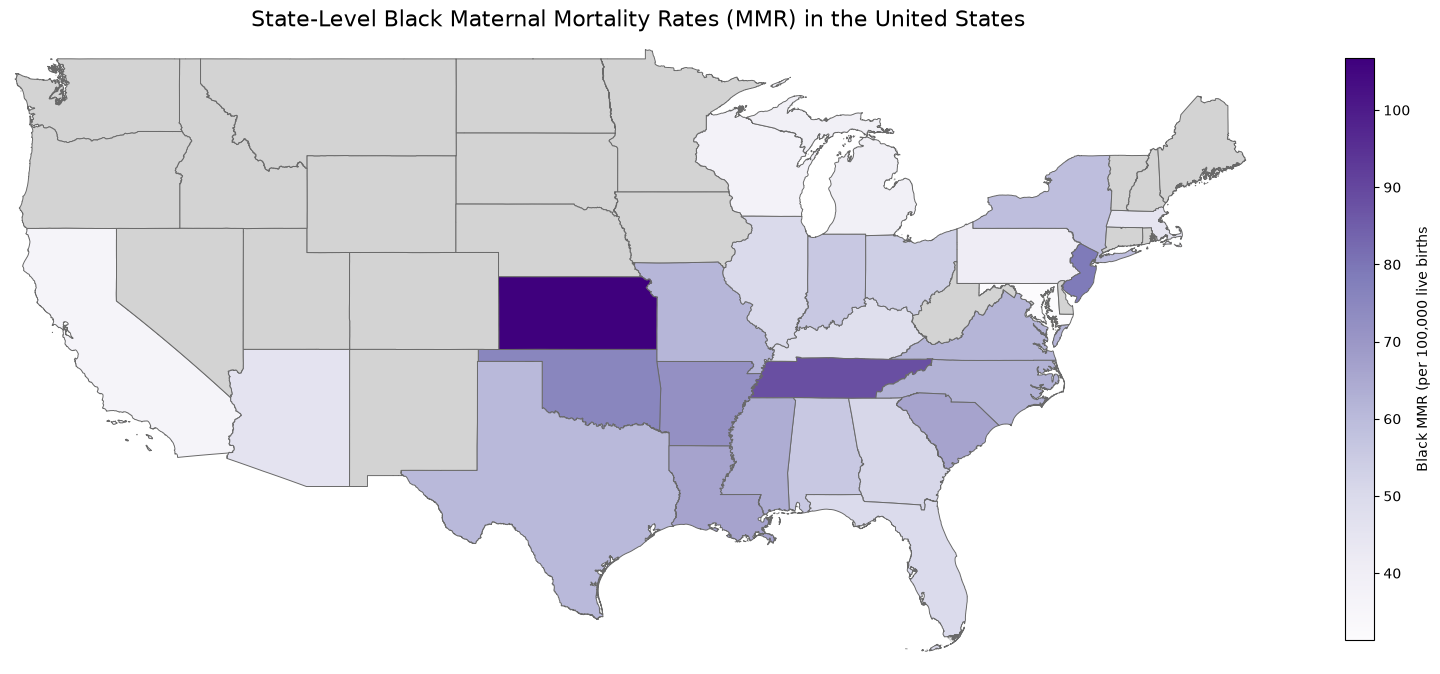

In [19]:
# Create a purple-gradient map of black maternal mortality rates by state

fig, ax = plt.subplots(figsize = (16,10))

map_data.plot(
    column = "BLACK_MMR",
    cmap ="Purples",
    linewidth = 0.7,
    edgecolor ="dimgray",
    legend =True,
    missing_kwds = {
        "color": "lightgrey",
        "label": "No data"
    },
    legend_kwds={
        "label": "Black MMR (per 100,000 live births",
        "shrink": 0.6
    },
    ax=ax
)

ax.set_title(
    "State-Level Black Maternal Mortality Rates (MMR) in the United States",
    fontsize = 16
)


ax.set_xlim(-125, -66)
ax.set_ylim(24, 50)
ax.axis("off")
plt.tight_layout()
plt.show()

# CDC Wonder Data Import

In [20]:
df_wonder = pd.read_csv("mmr_research_by_state.csv", encoding="UTF-8")

In [21]:
df_wonder.head(10)

,Notes,Year,Year Code,State,State Code,Single Race 6,Single Race 6 Code,Education,Education Code,ICD-10 113 Cause List,ICD-10 113 Cause List Code,Deaths,Population,Crude Rate,Crude Rate Lower 95% Confidence Interval,Crude Rate Upper 95% Confidence Interval
0,NaN,2024.0,2024.0,Alabama,1.0,American Indian or Alaska Native,1002-5,8th grade or less,1.0,"#Pregnancy, childbirth and the puerperium (O00...",GR113-105,0.0,Not Applicable,Not Applicable,Not Applicable,Not Applicable
1,NaN,2024.0,2024.0,Alabama,1.0,American Indian or Alaska Native,1002-5,8th grade or less,1.0,Pregnancy with abortive outcome (O00-O07),GR113-106,0.0,Not Applicable,Not Applicable,Not Applicable,Not Applicable
2,NaN,2024.0,2024.0,Alabama,1.0,American Indian or Alaska Native,1002-5,8th grade or less,1.0,"Other complications of pregnancy, childbirth a...",GR113-107,0.0,Not Applicable,Not Applicable,Not Applicable,Not Applicable
3,NaN,2024.0,2024.0,Alabama,1.0,American Indian or Alaska Native,1002-5,9th through 12th grade with no diploma,2.0,"#Pregnancy, childbirth and the puerperium (O00...",GR113-105,0.0,Not Applicable,Not Applicable,Not Applicable,Not Applicable
4,NaN,2024.0,2024.0,Alabama,1.0,American Indian or Alaska Native,1002-5,9th through 12th grade with no diploma,2.0,Pregnancy with abortive outcome (O00-O07),GR113-106,0.0,Not Applicable,Not Applicable,Not Applicable,Not Applicable
5,NaN,2024.0,2024.0,Alabama,1.0,American Indian or Alaska Native,1002-5,9th through 12th grade with no diploma,2.0,"Other complications of pregnancy, childbirth a...",GR113-107,0.0,Not Applicable,Not Applicable,Not Applicable,Not Applicable
6,NaN,2024.0,2024.0,Alabama,1.0,American Indian or Alaska Native,1002-5,High school graduate or GED completed,3.0,"#Pregnancy, childbirth and the puerperium (O00...",GR113-105,0.0,Not Applicable,Not Applicable,Not Applicable,Not Applicable
7,NaN,2024.0,2024.0,Alabama,1.0,American Indian or Alaska Native,1002-5,High school graduate or GED completed,3.0,Pregnancy with abortive outcome (O00-O07),GR113-106,0.0,Not Applicable,Not Applicable,Not Applicable,Not Applicable
8,NaN,2024.0,2024.0,Alabama,1.0,American Indian or Alaska Native,1002-5,High school graduate or GED completed,3.0,"Other complications of pregnancy, childbirth a...",GR113-107,0.0,Not Applicable,Not Applicable,Not Applicable,Not Applicable
9,NaN,2024.0,2024.0,Alabama,1.0,American Indian or Alaska Native,1002-5,"Some college credit, but not a degree.",4.0,"#Pregnancy, childbirth and the puerperium (O00...",GR113-105,0.0,Not Applicable,Not Applicable,Not Applicable,Not Applicable
